In [1]:
!pip install -q git+https://github.com/abhibarnwal707/PaperTrail.git
import os
from kaggle_secrets import UserSecretsClient
os.environ["DAGSHUB_USER_TOKEN"] = UserSecretsClient().get_secret("DAGSHUB_TOKEN")
import dagshub, mlflow
dagshub.init(repo_owner="abhibarnwal707", repo_name="papertrail", mlflow=True)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 83.8 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 84.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/22

Accessing as abhibarnwal707

Initialized MLflow to track repo "abhibarnwal707/papertrail"

Repository abhibarnwal707/papertrail initialized!

In [4]:
import glob
import time
import numpy as np
import polars as pl

path = glob.glob("/kaggle/input/datasets/abhibarnwal707/papertrail-processed/transactions.parquet", recursive=True)[0]
df = pl.read_parquet(path).sort(["ts", "txn_id"])
print(path, df.shape)

/kaggle/input/datasets/abhibarnwal707/papertrail-processed/transactions.parquet (5078345, 16)


In [5]:
# Split + shared evaluation helper (same protocol as 02_baseline)
from papertrail.features import add_out_count_24h
from papertrail.metrics import best_f1_threshold, evaluate
from papertrail.split import assert_valid_split, split_summary, temporal_split

df = add_out_count_24h(df)
summary = split_summary(df)
pl.Config.set_tbl_cols(-1)
print(summary)
assert_valid_split(summary)


def make_eval(val, test):
    y_val, y_test = val["label"].to_numpy(), test["label"].to_numpy()
    ach_test = (test["pay_format"] == "ACH").to_numpy()

    def run_eval(p_val, p_test):
        thr = best_f1_threshold(y_val, p_val)
        res = {"threshold": float(thr)}
        for k, v in evaluate(y_val, p_val, thr).items():
            res[f"val_{k}"] = v
        for k, v in evaluate(y_test, p_test, thr).items():
            res[f"test_{k}"] = v
        for k, v in evaluate(y_test[ach_test], p_test[ach_test], thr).items():
            res[f"test_ach_{k}"] = v
        return res

    return y_val, y_test, run_eval


train, val, test = temporal_split(df)
y_val, y_test, run_eval = make_eval(val, test)


shape: (4, 6)
┌──────────────┬─────────┬───────────┬──────────┬─────────────────────┬─────────────────────┐
│ split        ┆ rows    ┆ positives ┆ pos_rate ┆ start               ┆ end                 │
│ ---          ┆ ---     ┆ ---       ┆ ---      ┆ ---                 ┆ ---                 │
│ str          ┆ i64     ┆ i64       ┆ f64      ┆ datetime[μs]        ┆ datetime[μs]        │
╞══════════════╪═════════╪═══════════╪══════════╪═════════════════════╪═════════════════════╡
│ train        ┆ 3248921 ┆ 2530      ┆ 0.000779 ┆ 2022-09-01 00:00:00 ┆ 2022-09-06 23:59:00 │
│ val          ┆ 965524  ┆ 1036      ┆ 0.001073 ┆ 2022-09-07 00:00:00 ┆ 2022-09-08 23:59:00 │
│ test         ┆ 862792  ┆ 956       ┆ 0.001108 ┆ 2022-09-09 00:00:00 ┆ 2022-09-10 23:59:00 │
│ dropped_tail ┆ 1108    ┆ 655       ┆ 0.591155 ┆ 2022-09-11 00:05:00 ┆ 2022-09-18 16:18:00 │
└──────────────┴─────────┴───────────┴──────────┴─────────────────────┴─────────────────────┘


In [6]:
# rules_v2 (the send-count threshold is now chosen on TRAINING data and actually fires)
from papertrail.rules import fit_rule_params_v2, rule_flags, rule_score

params_v2, burst_table = fit_rule_params_v2(train)
print(burst_table)
print(params_v2)

flags = rule_flags(val, params_v2)
for c in ["r_high_amount", "r_ach_band", "r_burst"]:
    fired = flags[c].to_numpy()
    tp = int((fired & (y_val == 1)).sum())
    print(f"{c:15s} flagged={int(fired.sum()):8d}  precision={tp / max(int(fired.sum()), 1):.4f}  "
          f"recall={tp / int(y_val.sum()):.3f}")

with mlflow.start_run(run_name="rules_v2"):
    mlflow.log_params({f"rule_{k}": v for k, v in params_v2.items()})
    rules2_res = run_eval(rule_score(val, params_v2), rule_score(test, params_v2))
    mlflow.log_metrics(rules2_res)
print({k: round(v, 4) for k, v in rules2_res.items() if k.startswith("test_") and "ach" not in k})


shape: (9, 5)
┌────────┬─────────┬─────┬───────────┬──────────┐
│ burst  ┆ flagged ┆ tp  ┆ precision ┆ lift     │
│ ---    ┆ ---     ┆ --- ┆ ---       ┆ ---      │
│ f64    ┆ i64     ┆ i64 ┆ f64       ┆ f64      │
╞════════╪═════════╪═════╪═══════════╪══════════╡
│ 5.0    ┆ 1063388 ┆ 661 ┆ 0.000622  ┆ 0.798231 │
│ 10.0   ┆ 550394  ┆ 482 ┆ 0.000876  ┆ 1.124584 │
│ 20.0   ┆ 303431  ┆ 399 ┆ 0.001315  ┆ 1.688619 │
│ 50.0   ┆ 269574  ┆ 389 ┆ 0.001443  ┆ 1.853063 │
│ 100.0  ┆ 268848  ┆ 387 ┆ 0.001439  ┆ 1.848514 │
│ 200.0  ┆ 267334  ┆ 386 ┆ 0.001444  ┆ 1.854179 │
│ 500.0  ┆ 260122  ┆ 373 ┆ 0.001434  ┆ 1.841409 │
│ 1000.0 ┆ 234948  ┆ 333 ┆ 0.001417  ┆ 1.820083 │
│ 5000.0 ┆ 147732  ┆ 220 ┆ 0.001489  ┆ 1.912347 │
└────────┴─────────┴─────┴───────────┴──────────┘
{'amt_high': 15952734.67, 'burst': 5000.0}
r_high_amount   flagged=    7020  precision=0.0019  recall=0.013
r_ach_band      flagged=   26685  precision=0.0196  recall=0.505
r_burst         flagged=   59986  precision=0.0013  recall=0.07

In [7]:
# %% Cell 5: DRY RUN of the history features on the first 500K rows (checks speed and errors)
from papertrail.graph_features import HISTORY_FEATURES, add_history_features

small = df.head(500_000)
t0 = time.time()
small_f = add_history_features(small)
print(f"500K rows in {time.time() - t0:.0f}s ->", small_f.shape)
print(small_f.select(HISTORY_FEATURES).describe())
# Full data is about 10x this (and the event table doubles it). If this took more than ~5 min, ask for help first.


500K rows in 8s -> (500000, 52)
shape: (9, 36)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ sta ┆ s_o ┆ s_o ┆ s_i ┆ s_i ┆ s_o ┆ s_o ┆ s_i ┆ s_i ┆ s_o ┆ s_i ┆ s_u ┆ s_u ┆ s_t ┆ s_t ┆ s_g ┆ s_a ┆ d_o ┆ d_o ┆ d_i ┆ d_i ┆ d_o ┆ d_o ┆ d_i ┆ d_i ┆ d_o ┆ d_i ┆ d_u ┆ d_u ┆ d_t ┆ d_t ┆ d_g ┆ d_a ┆ has ┆ s_p ┆ d_p │
│ tis ┆ ut_ ┆ ut_ ┆ n_c ┆ n_c ┆ ut_ ┆ ut_ ┆ n_s ┆ n_s ┆ ut_ ┆ n_m ┆ niq ┆ niq ┆ ot_ ┆ ot_ ┆ ap_ ┆ ge_ ┆ ut_ ┆ ut_ ┆ n_c ┆ n_c ┆ ut_ ┆ ut_ ┆ n_s ┆ n_s ┆ ut_ ┆ n_m ┆ niq ┆ niq ┆ ot_ ┆ ot_ ┆ ap_ ┆ ge_ ┆ _re ┆ age ┆ age │
│ tic ┆ cnt ┆ cnt ┆ nt_ ┆ nt_ ┆ sum ┆ sum ┆ um_ ┆ um_ ┆ mea ┆ ean ┆ _ou ┆ _in ┆ out ┆ in  ┆ s   ┆ s   ┆ cnt ┆ cnt ┆ nt_ ┆ nt_ ┆ sum ┆ sum ┆ um_ ┆ um_ ┆ mea ┆ ean ┆ _ou ┆ _in ┆ out ┆ in  ┆ s   ┆ s   ┆ ver ┆ ran ┆ ran │
│ --- ┆ _24 ┆ _7d ┆ 24h ┆ 7d  ┆ _24 ┆ _7d ┆ 24h ┆ 7d  ┆ n_7 ┆ _7d ┆ t   ┆ --- ┆ -

In [8]:
# history + graph features for ALL rows (past-only), then save them
t0 = time.time()
dfx = add_history_features(df)
print(f"all rows in {time.time() - t0:.0f}s ->", dfx.shape)
dfx.select(["txn_id"] + HISTORY_FEATURES).write_parquet("/kaggle/working/features_v2.parquet")


all rows in 46s -> (5078345, 52)


(3248921, 51) scale_pos_weight = 1283.2
[0]	validation_0-aucpr:0.02328
[50]	validation_0-aucpr:0.34217
[118]	validation_0-aucpr:0.36312


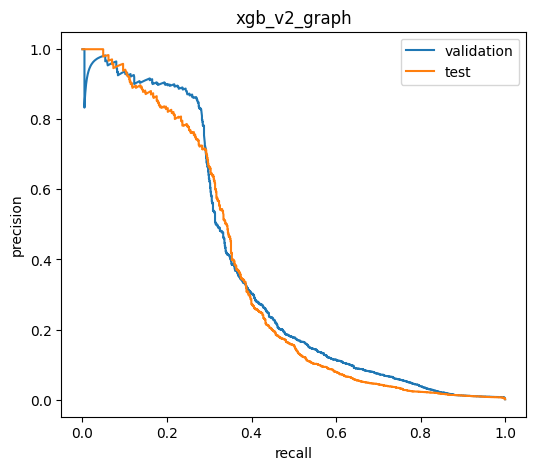

🏃 View run xgb_v2_graph at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0/runs/094bf68abb6244e38a45d37c1702d445
🧪 View experiment at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0
shape: (51, 2)
┌───────────────────┬──────────┐
│ feature           ┆ gain     │
│ ---               ┆ ---      │
│ str               ┆ f64      │
╞═══════════════════╪══════════╡
│ fmt_ACH           ┆ 0.40123  │
│ is_ach            ┆ 0.304368 │
│ s_uniq_out        ┆ 0.100127 │
│ is_cross_currency ┆ 0.018383 │
│ s_out_cnt_24h     ┆ 0.014748 │
│ s_gap_s           ┆ 0.013557 │
│ fmt_Cheque        ┆ 0.013409 │
│ log_amt           ┆ 0.006801 │
│ d_gap_s           ┆ 0.006247 │
│ is_same_bank      ┆ 0.005399 │
│ s_tot_out         ┆ 0.00525  │
│ s_out_sum_24h     ┆ 0.004751 │
│ in_amount_band    ┆ 0.004632 │
│ d_in_mean_7d      ┆ 0.004272 │
│ s_out_cnt_7d      ┆ 0.004247 │
│ …                 ┆ …        │
│ d_out_cnt_7d      ┆ 0.002385 │
│ d_out_sum_24h     ┆ 0.002363 │


In [9]:
# XGBoost v2 = v1 tabular features + history/graph features
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import precision_recall_curve

from papertrail.features import build_features, fit_categories

train, val, test = temporal_split(dfx)     # same split, now with the extra columns
cats = fit_categories(train)


def to_matrix(part):
    base = build_features(part, cats)
    return pl.concat([base, part.select(HISTORY_FEATURES)], how="horizontal").cast(pl.Float32)


Xtr_df, Xva_df, Xte_df = to_matrix(train), to_matrix(val), to_matrix(test)
feat_names = Xtr_df.columns
X_train, X_val, X_test = Xtr_df.to_numpy(), Xva_df.to_numpy(), Xte_df.to_numpy()   # nulls become NaN
y_train = train["label"].to_numpy()
spw = float((y_train == 0).sum() / y_train.sum())
print(X_train.shape, "scale_pos_weight =", round(spw, 1))

xgb_params = dict(
    tree_method="hist", n_estimators=1000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
    eval_metric="aucpr", early_stopping_rounds=50, n_jobs=-1, random_state=0,
)
model = xgb.XGBClassifier(**xgb_params)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)

p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

with mlflow.start_run(run_name="xgb_v2_graph"):
    mlflow.log_params({k: v for k, v in xgb_params.items() if k != "eval_metric"})
    mlflow.log_param("n_features", len(feat_names))
    mlflow.log_param("best_iteration", int(model.best_iteration))
    xgb2_res = run_eval(p_val, p_test)
    mlflow.log_metrics(xgb2_res)

    fig, ax = plt.subplots(figsize=(6, 5))
    for name, y, p in (("validation", y_val, p_val), ("test", y_test, p_test)):
        pr, rc, _ = precision_recall_curve(y, p)
        ax.plot(rc, pr, label=name)
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_title("xgb_v2_graph")
    ax.legend()
    mlflow.log_figure(fig, "pr_curve.png")
    plt.show()

    model.save_model("/kaggle/working/xgb_v2.json")
    mlflow.log_artifact("/kaggle/working/xgb_v2.json")
    imp = pl.DataFrame({"feature": feat_names, "gain": model.feature_importances_.tolist()}).sort(
        "gain", descending=True)
    imp.write_csv("/kaggle/working/xgb_v2_importance.csv")
    mlflow.log_artifact("/kaggle/working/xgb_v2_importance.csv")
pl.Config.set_tbl_rows(30)
print(imp)


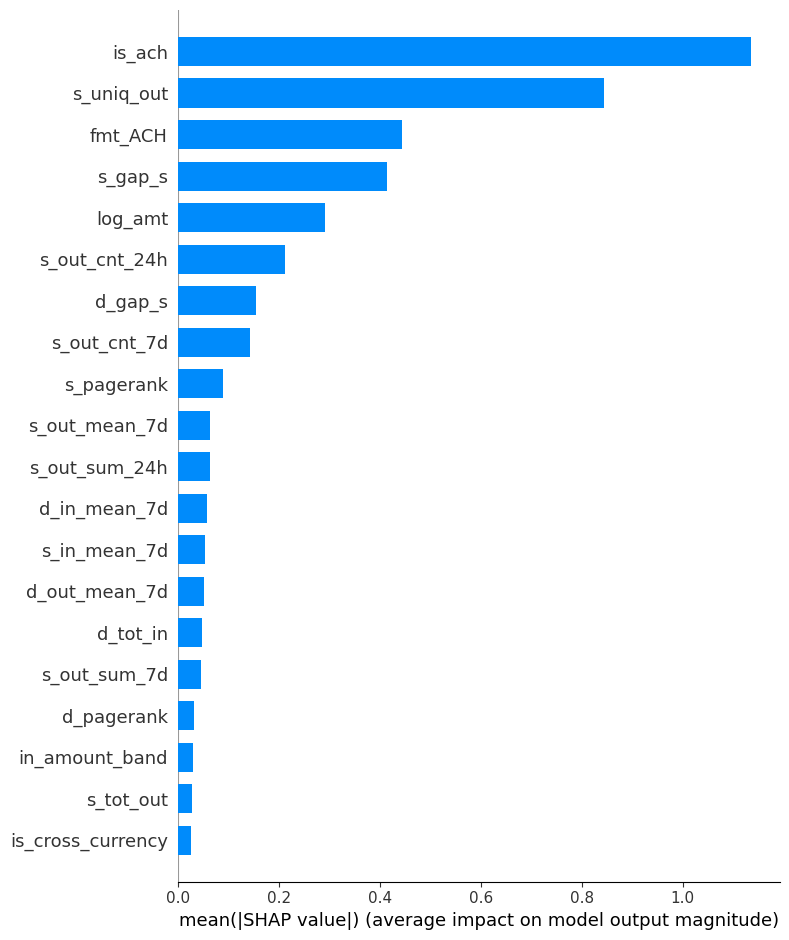

🏃 View run xgb_v2_graph_shap at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0/runs/f9575776af98458a8a6ec08dc3a1dd4c
🧪 View experiment at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0


In [11]:
# SHAP on a validation sample (a failure here must not lose the run above)
try:
    import shap

    rng = np.random.default_rng(0)
    pick = rng.choice(len(X_val), size=20_000, replace=False)
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_val[pick])
    plt.figure()
    shap.summary_plot(sv, X_val[pick], feature_names=feat_names, plot_type="bar", max_display=20, show=False)
    plt.tight_layout()
    plt.savefig("/kaggle/working/shap_v2.png", dpi=150)
    plt.show()
    with mlflow.start_run(run_name="xgb_v2_graph_shap"):
        mlflow.log_artifact("/kaggle/working/shap_v2.png")
except Exception as e:  # noqa: BLE001
    print("SHAP failed, continuing without it:", repr(e))


In [12]:
# Comparison table (test split) + files to download
import json
import urllib.request

try:  # earlier results from the repo, so the table has all four rows
    url = "https://raw.githubusercontent.com/abhibarnwal707/PaperTrail/main/reports/baseline_metrics.json"
    old = json.load(urllib.request.urlopen(url))
except Exception as e:  # noqa: BLE001
    print("could not fetch baseline_metrics.json from GitHub:", repr(e))
    old = {}

runs = []
if "rules_baseline" in old:
    runs.append(("Rules (v1)", old["rules_baseline"]))
runs.append(("Rules v2", rules2_res))
if "xgb_v1_tabular" in old:
    runs.append(("XGB tabular", old["xgb_v1_tabular"]))
runs.append(("XGB + graph (v2)", xgb2_res))

table = pl.DataFrame([{
    "Model": n,
    "PR-AUC": r["test_pr_auc"], "F1 (minority)": r["test_f1"],
    "Recall@1%FPR": r["test_recall_at_1pct_fpr"], "Precision@1000": r["test_precision_at_1000"],
    "ACH-only PR-AUC": r["test_ach_pr_auc"], "ACH-only F1": r["test_ach_f1"],
} for n, r in runs])
print(f"test positives: {int(y_test.sum())} of {len(y_test)} (base rate {y_test.mean():.4%})")
print(table)

table.write_csv("/kaggle/working/comparison_table.csv")
with open("/kaggle/working/phase4_metrics.json", "w") as fh:
    json.dump({"rules_v2": rules2_res, "xgb_v2_graph": xgb2_res, "rule_params_v2": params_v2,
               "burst_candidates": burst_table.to_dicts(), "scale_pos_weight": spw,
               "best_iteration": int(model.best_iteration)}, fh, indent=2)
print("commit message idea:",
      f"Add as-of + PageRank features, XGB v2: PR-AUC {old.get('xgb_v1_tabular', {}).get('test_pr_auc', float('nan')):.3f}"
      f" -> {xgb2_res['test_pr_auc']:.3f}")
# Download comparison_table.csv, phase4_metrics.json, xgb_v2_importance.csv and shap_v2.png from the Output tab
# into PaperTrail/reports/ (features_v2.parquet is large: keep it in Kaggle, do not commit it).


test positives: 956 of 862792 (base rate 0.1108%)
shape: (4, 7)
┌───────────────┬──────────┬───────────────┬───────────────┬──────────────┬──────────┬─────────────┐
│ Model         ┆ PR-AUC   ┆ F1 (minority) ┆ Recall@1%FPR  ┆ Precision@10 ┆ ACH-only ┆ ACH-only F1 │
│ ---           ┆ ---      ┆ ---           ┆ ---           ┆ 00           ┆ PR-AUC   ┆ ---         │
│ str           ┆ f64      ┆ f64           ┆ f64           ┆ ---          ┆ ---      ┆ f64         │
│               ┆          ┆               ┆               ┆ f64          ┆ f64      ┆             │
╞═══════════════╪══════════╪═══════════════╪═══════════════╪══════════════╪══════════╪═════════════╡
│ Rules (v1)    ┆ 0.007986 ┆ 0.030262      ┆ 0.011506      ┆ 0.0          ┆ 0.019062 ┆ 0.049308    │
│ Rules v2      ┆ 0.006988 ┆ 0.024804      ┆ 0.013598      ┆ 0.0          ┆ 0.019062 ┆ 0.049843    │
│ XGB tabular   ┆ 0.046082 ┆ 0.116461      ┆ 0.408996      ┆ 0.116        ┆ 0.0524   ┆ 0.121274    │
│ XGB + graph   ┆ 0.351189 